In [1]:
import numpy as np
from sklearn.datasets import load_iris 
from sklearn.linear_model import Perceptron 

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = (iris.target == 0)

per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

X_new = [[2, 0.5], [3, 1]]
y_pred = per_clf.predict(X_new)

In [2]:
y_pred

array([ True, False])

In [3]:
y

0       True
1       True
2       True
3       True
4       True
       ...  
145    False
146    False
147    False
148    False
149    False
Name: target, Length: 150, dtype: bool

In [4]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)




In [5]:
rmse

0.5053326657968684

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error

dummy = make_pipeline(
    StandardScaler(),
    DummyRegressor(strategy="mean")
)

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_valid)

dummy_rmse = root_mean_squared_error(y_valid, dummy_pred)

print("Baseline rmse : ", dummy_rmse)
print("Neural Network rmse : ", rmse)

Baseline rmse :  1.1476260241965577
Neural Network rmse :  0.5053326657968684


In [7]:
from sklearn.ensemble import RandomForestRegressor

rfr = make_pipeline(
    StandardScaler(),
    RandomForestRegressor(random_state=42)
)

rfr.fit(X_train, y_train)

rfr_pred = rfr.predict(X_valid)

rfr_rmse = root_mean_squared_error(y_valid, rfr_pred)

print("Random Forest rmse: ", rfr_rmse)

Random Forest rmse:  0.5073847566107056


In [8]:
from sklearn.neural_network import MLPClassifier

iris = load_iris()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlpc = MLPClassifier(hidden_layer_sizes=[5])

pipeline = make_pipeline(StandardScaler(),
                         mlpc
)

pipeline.fit(X_train, y_train)

mlpc_pred = pipeline.predict(X_valid)

mlpc_rmse  = root_mean_squared_error(y_valid, mlpc_pred)
print("MLPClassifier rmse : ", mlpc_rmse)

MLPClassifier rmse :  0.4225771273642583


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [9]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, mlpc_pred)

print("MLPClassifier Accuracy:", accuracy)

MLPClassifier Accuracy: 0.8214285714285714


In [10]:
from sklearn.neural_network import MLPClassifier

iris = load_iris()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    iris.data, iris.target, random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlpc = MLPClassifier(hidden_layer_sizes=[10])

pipeline = make_pipeline(StandardScaler(),
                         mlpc
)

pipeline.fit(X_train, y_train)

mlpc_pred = pipeline.predict(X_valid)

mlpc_rmse  = root_mean_squared_error(y_valid, mlpc_pred)
print("MLPClassifier rmse : ", mlpc_rmse)

MLPClassifier rmse :  0.4225771273642583


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [11]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_valid, mlpc_pred)

print("MLPClassifier Accuracy:", accuracy)

MLPClassifier Accuracy: 0.8214285714285714


In [12]:
import tensorflow as tf 

fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist 
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

I0000 00:00:1794320937.511929    6776 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [13]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (55000, 28, 28) (55000,)
Validation: (5000, 28, 28) (5000,)
Testing: (10000, 28, 28) (10000,)


In [14]:
X_train, X_valid, X_test = (
    X_train / 255. ,
    X_valid / 255. ,
    X_test / 255. 
)

In [15]:
print(X_train.min())
print(X_train.max())
print(X_train.dtype)

0.0
1.0
float64


In [16]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker","Bag", "Ankle boot"]

In [17]:
class_names[y_train[8]]

'Sandal'

In [18]:
class_names[y_train[4]]

'T-shirt/top'

In [19]:
tf.random.set_seed(42)

model = tf.keras.Sequential()

model.add(tf.keras.layers.Input(shape=[28, 28]))

model.add(tf.keras.layers.Flatten())

model.add(tf.keras.layers.Dense(300,activation="relu"))

model.add(tf.keras.layers.Dense(100,activation="relu"))

model.add(tf.keras.layers.Dense(10,activation="softmax"))
 

W0000 00:00:1794320945.241245    6776 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [20]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=[28, 28]),
    tf.keras.layers.Dense(300, activation="relu"),
    tf.keras.layers.Dense(100, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [21]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

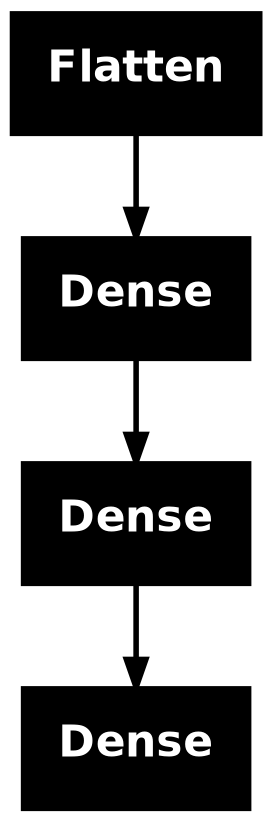

In [22]:
tf.keras.utils.plot_model(model)

In [23]:
model.layers

[<Flatten name=flatten_1, built=True>,
 <Dense name=dense_3, built=True>,
 <Dense name=dense_4, built=True>,
 <Dense name=dense_5, built=True>]

In [24]:
hidden1 = model.layers[1]

In [25]:
hidden1

<Dense name=dense_3, built=True>

In [26]:
model.get_layer('dense_3') is hidden1

True

In [27]:
weights, biases = hidden1.get_weights()

In [28]:
weights

array([[-0.04881736,  0.01628484,  0.04838143, ...,  0.02192262,
        -0.05207869, -0.02247028],
       [ 0.00792997, -0.01992248, -0.05918198, ..., -0.03368679,
         0.03742746,  0.06774482],
       [ 0.01422118, -0.03848087,  0.02173252, ..., -0.02076484,
        -0.0273984 ,  0.00673914],
       ...,
       [ 0.00979272, -0.01992043, -0.03961558, ...,  0.05668131,
        -0.07211236, -0.0086235 ],
       [ 0.06124234,  0.02977872,  0.05485146, ..., -0.0188271 ,
        -0.05237217, -0.05947071],
       [ 0.02939088, -0.04145118,  0.00421487, ...,  0.07163091,
        -0.05926377,  0.0366797 ]], shape=(784, 300), dtype=float32)

In [29]:
weights.shape


(784, 300)

In [30]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [31]:
biases.shape

(300,)

In [32]:
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="sgd",
              metrics=["accuracy"])

In [33]:
history = model.fit(X_train, y_train, epochs=30,
                    validation_data=(X_valid, y_valid))

Epoch 1/30


W0000 00:00:1794320946.628744    6776 cpu_allocator_impl.cc:82] Allocation of 172480000 exceeds 10% of free system memory.


1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7649 - loss: 0.7217 - val_accuracy: 0.8230 - val_loss: 0.5133
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8293 - loss: 0.4910 - val_accuracy: 0.8348 - val_loss: 0.4620
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8440 - loss: 0.4452 - val_accuracy: 0.8458 - val_loss: 0.4361
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8533 - loss: 0.4168 - val_accuracy: 0.8516 - val_loss: 0.4194
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8603 - loss: 0.3958 - val_accuracy: 0.8524 - val_loss: 0.4073
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8662 - loss: 0.3794 - val_accuracy: 0.8552 - val_loss: 0.3972
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8704 - loss: 0.3657 - val_accuracy: 0.8562 - val_loss: 0.3893
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8747 - loss: 0.3539 - val_accurac

In [34]:
history.params

{'verbose': 'auto', 'epochs': 30, 'steps': 1719}

In [35]:
history.epoch

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29]

In [36]:
history.history

{'accuracy': [0.7649454474449158,
  0.8292909264564514,
  0.844036340713501,
  0.8532727360725403,
  0.8602545261383057,
  0.8661636114120483,
  0.8703636527061462,
  0.8747090697288513,
  0.8785272836685181,
  0.8817636370658875,
  0.8847272992134094,
  0.8875091075897217,
  0.8902909159660339,
  0.8925636410713196,
  0.8954181671142578,
  0.8974727392196655,
  0.8999454379081726,
  0.9017636179924011,
  0.9034363627433777,
  0.9052727222442627,
  0.9075999855995178,
  0.9095273017883301,
  0.9113090634346008,
  0.9128545522689819,
  0.9143818020820618,
  0.9160363674163818,
  0.9173091053962708,
  0.9190000295639038,
  0.9210181832313538,
  0.9224545359611511],
 'loss': [0.7216796875,
  0.4910086393356323,
  0.44522079825401306,
  0.4167785942554474,
  0.39575859904289246,
  0.3793767988681793,
  0.3656795918941498,
  0.35386794805526733,
  0.34341931343078613,
  0.33390313386917114,
  0.3252303898334503,
  0.31718799471855164,
  0.30964699387550354,
  0.3025652766227722,
  0.2958559

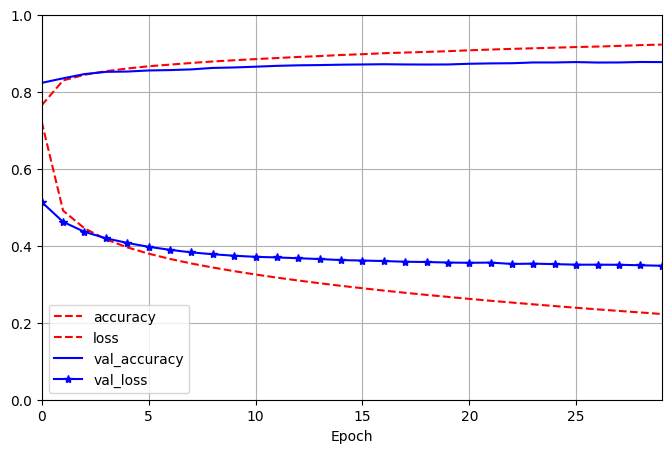

In [37]:
import matplotlib.pyplot as plt
import pandas as pd

pd.DataFrame(history.history).plot(
    figsize=(8,5), xlim=[0,29], ylim=[0, 1], xlabel="Epoch", style=["r--", "r--", "b-","b-*"])
plt.grid()
plt.show()


In [38]:
model.evaluate(X_test, y_test)

191/313 ━━━━━━━━━━━━━━━━━━━━ 0s 793us/step - accuracy: 0.8721 - loss: 0.3779

W0000 00:00:1794321014.805965    6776 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 825us/step - accuracy: 0.8770 - loss: 0.3618


[0.36178475618362427, 0.8769999742507935]

In [39]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.08, 0.  , 0.01, 0.  , 0.91],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      dtype=float32)

In [40]:
y_test[:3]

array([9, 2, 1], dtype=uint8)

In [41]:
import numpy as np
y_pred = y_proba.argmax(axis=1)
y_pred

array([9, 2, 1])

In [42]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42
)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)

In [43]:
tf.random.set_seed(42)
norm_layer = tf.keras.layers.Normalization(input_shape=X_train.shape[1:])
model = tf.keras.Sequential([
    norm_layer,
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(50, activation="relu"),
    tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse", optimizer=optimizer, metrics=["root_mean_squared_error"])
norm_layer.adapt(X_train)
history = model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))
mse_test , rmse_test = model.evaluate(X_test, y_test)

Epoch 1/20


/home/chintu/miniconda3/envs/ml-ops/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.8282 - root_mean_squared_error: 0.9101 - val_loss: 0.4408 - val_root_mean_squared_error: 0.6639
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3682 - root_mean_squared_error: 0.6068 - val_loss: 0.3300 - val_root_mean_squared_error: 0.5745
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3405 - root_mean_squared_error: 0.5835 - val_loss: 0.3281 - val_root_mean_squared_error: 0.5728
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3262 - root_mean_squared_error: 0.5712 - val_loss: 0.3775 - val_root_mean_squared_error: 0.6144
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3158 - root_mean_squared_error: 0.5619 - val_loss: 0.3044 - val_root_mean_squared_error: 0.5518
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3093 - root_mean_squared_error: 0.5562 - val_loss: 0.4014 - val_root_mean_squared_error: 0.6336
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3

In [44]:
X_new = X_test[:3]
y_pred = model.predict(X_new)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


array([[0.3284528],
       [1.0667007],
       [5.084839 ]], dtype=float32)

In [45]:
X_new.shape

(3, 8)

In [46]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])

In [47]:
normalization_layer = tf.keras.layers.Normalization()
hidden_layer1 = tf.keras.layers.Dense(30, activation="relu")
hidden_layer2 = tf.keras.layers.Dense(30, activation="relu")
concat_layer  = tf.keras.layers.Concatenate()
output_layer = tf.keras.layers.Dense(1)

input_ = tf.keras.layers.Input(shape=X_train.shape[1:])
normalized = normalization_layer(input_)
hidden1 = hidden_layer1(normalized)
hidden2 = hidden_layer2(hidden1)
concat = concat_layer([normalized, hidden2])
output = output_layer(concat)

model = tf.keras.Model(inputs=[input_], outputs=[output])
model.compile(loss="mse", optimizer="adam", metrics=["root_mean_squared_error"])
normalization_layer.adapt(X_train)
model.fit(X_train, y_train, epochs=20, validation_data=(X_valid, y_valid))


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.1203 - root_mean_squared_error: 1.0584 - val_loss: 0.9373 - val_root_mean_squared_error: 0.9682
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 975us/step - loss: 0.4632 - root_mean_squared_error: 0.6806 - val_loss: 0.8191 - val_root_mean_squared_error: 0.9051
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 994us/step - loss: 0.4045 - root_mean_squared_error: 0.6360 - val_loss: 1.3050 - val_root_mean_squared_error: 1.1424
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3801 - root_mean_squared_error: 0.6166 - val_loss: 1.4001 - val_root_mean_squared_error: 1.1833
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 972us/step - loss: 0.3796 - root_mean_squared_error: 0.6161 - val_loss: 3.2240 - val_root_mean_squared_error: 1.7955
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 989us/step - loss: 0.3716 - root_mean_squared_error: 0.6096 - val_loss: 4.0469 - val_root_mean_squared_error: 2.0117
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 9

In [48]:
X_new = X_test[:3]
X_new.shape

(3, 8)

In [49]:
y_pred = model.predict(X_new)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


array([[0.6957332],
       [1.40363  ],
       [4.213878 ]], dtype=float32)

In [50]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])

In [53]:
input_wide = tf.keras.layers.Input(shape=[5])
input_deep = tf.keras.layers.Input(shape=[6])

norm_layer_wide = tf.keras.layers.Normalization()
norm_layer_deep = tf.keras.layers.Normalization()

norm_wide = norm_layer_wide(input_wide)
norm_deep = norm_layer_deep(input_deep)

hidden1 = tf.keras.layers.Dense(30, activation="relu")(norm_deep)
hidden2 = tf.keras.layers.Dense(30, activation="relu")(hidden1)

concat = tf.keras.layers.concatenate([norm_wide, hidden2])

output = tf.keras.layers.Dense(1)(concat)

model = tf.keras.Model(inputs=[input_wide, input_deep], outputs=[output])

In [54]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss="mse", optimizer=optimizer, metrics=["root_mean_squared_error"])

X_train_wide, X_train_deep = X_train[:, :5], X_train[:, 2:]
X_valid_wide, X_valid_deep = X_valid[:, :5], X_valid[:, 2:]
X_test_wide, X_test_deep = X_test[:, :5], X_test[:, 2:]
X_new_wide, X_new_deep = X_test_wide[:3], X_test_deep[:3]
norm_layer_wide.adapt(X_train_wide)
norm_layer_deep.adapt(X_train_deep)
history = model.fit((X_train_wide, X_train_deep), y_train, epochs=20,
 validation_data=((X_valid_wide, X_valid_deep), y_valid))
mse_test = model.evaluate((X_test_wide, X_test_deep), y_test)
y_pred = model.predict((X_new_wide, X_new_deep))



Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1.4007 - root_mean_squared_error: 1.1835 - val_loss: 0.8674 - val_root_mean_squared_error: 0.9313
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.5169 - root_mean_squared_error: 0.7190 - val_loss: 0.4472 - val_root_mean_squared_error: 0.6687
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4430 - root_mean_squared_error: 0.6656 - val_loss: 0.4009 - val_root_mean_squared_error: 0.6332
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4111 - root_mean_squared_error: 0.6412 - val_loss: 0.6421 - val_root_mean_squared_error: 0.8013
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3890 - root_mean_squared_error: 0.6237 - val_loss: 0.5394 - val_root_mean_squared_error: 0.7345
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3804 - root_mean_squared_error: 0.6167 - val_loss: 1.6898 - val_root_mean_squared_error: 1.2999
Epoch 7/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 

In [55]:
X_test.shape

(5160, 8)

In [56]:
X_train_wide.shape

(11610, 5)

In [57]:
X_train_deep.shape

(11610, 6)

In [58]:
y_pred

array([[0.4837731],
       [1.2835448],
       [3.618422 ]], dtype=float32)

In [59]:
y_test[:3]

array([0.477  , 0.458  , 5.00001])

In [69]:

input_wide = tf.keras.layers.Input(shape=[5])
input_deep = tf.keras.layers.Input(shape=[6])

norm_layer_wide = tf.keras.layers.Normalization()
norm_layer_deep = tf.keras.layers.Normalization()

norm_wide = norm_layer_wide(input_wide)
norm_deep = norm_layer_deep(input_deep)

hidden1 = tf.keras.layers.Dense(30, activation="relu")(norm_deep)
hidden2 = tf.keras.layers.Dense(30, activation="relu")(hidden1)

concat = tf.keras.layers.concatenate([norm_wide, hidden2])

output = tf.keras.layers.Dense(1)(concat)
aux_output = tf.keras.layers.Dense(1)(hidden2)

model = tf.keras.Model(
    inputs=[input_wide, input_deep],
    outputs=[output, aux_output]
)

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

model.compile(
    loss=("mse", "mse"),
    loss_weights=(0.9, 0.1),
    optimizer=optimizer,
    metrics=["RootMeanSquaredError", "RootMeanSquaredError"]
)

norm_layer_wide.adapt(X_train_wide)
norm_layer_deep.adapt(X_train_deep)

history = model.fit(
    (X_train_wide, X_train_deep),
    (y_train, y_train),
    epochs=20,
    validation_data=(
        (X_valid_wide, X_valid_deep),
        (y_valid, y_valid)
    )
)


Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - dense_43_RootMeanSquaredError: 1.1906 - dense_43_loss: 1.4172 - dense_44_RootMeanSquaredError: 1.3996 - dense_44_loss: 1.9584 - loss: 1.4716 - val_dense_43_RootMeanSquaredError: 0.9060 - val_dense_43_loss: 0.8206 - val_dense_44_RootMeanSquaredError: 1.2971 - val_dense_44_loss: 1.6821 - val_loss: 0.9071
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - dense_43_RootMeanSquaredError: 0.7134 - dense_43_loss: 0.5090 - dense_44_RootMeanSquaredError: 0.9094 - dense_44_loss: 0.8270 - loss: 0.5408 - val_dense_43_RootMeanSquaredError: 0.7218 - val_dense_43_loss: 0.5209 - val_dense_44_RootMeanSquaredError: 0.8208 - val_dense_44_loss: 0.6736 - val_loss: 0.5363
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - dense_43_RootMeanSquaredError: 0.6562 - dense_43_loss: 0.4307 - dense_44_RootMeanSquaredError: 0.7797 - dense_44_loss: 0.6079 - loss: 0.4484 - val_dense_43_RootMeanSquaredError: 0.6588 - val_dense_43_loss: 0.4339 - val_dense_44_Ro

In [71]:
eval_results = model.evaluate((X_test_wide, X_test_deep), (y_test, y_test), return_dict=True)

weighted_sum_of_losses, main_loss, aux_loss, main_rmse, aux_rmse = eval_results


162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 761us/step - dense_43_RootMeanSquaredError: 0.5717 - dense_43_loss: 0.3266 - dense_44_RootMeanSquaredError: 0.6247 - dense_44_loss: 0.3905 - loss: 0.3332


In [72]:
y_pred_main , y_pred_aux = model.predict((X_new_wide, X_new_deep))

y_pred_tuple = model.predict((X_new_wide, X_new_deep))
y_pred = dict(zip(model.output_names, y_pred_tuple))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
